# K-Means Clustering

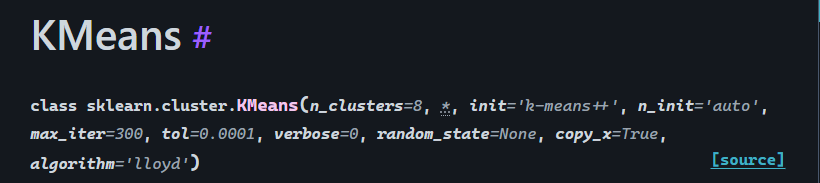

In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
import seaborn as sns
import os
os.chdir("E:/Vishal_Adesh/CDAC/Machine Learning/Datasets")
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

In [3]:
df = pd.read_csv("milk.csv",index_col=0)
df.head()

,water,protein,fat,lactose,ash
Animal,,,,,
HORSE,90.1,2.6,1.0,6.9,0.35
ORANGUTAN,88.5,1.4,3.5,6.0,0.24
MONKEY,88.4,2.2,2.7,6.4,0.18
DONKEY,90.3,1.7,1.4,6.2,0.40
HIPPO,90.4,0.6,4.5,4.4,0.10


In [4]:
# within sum of squares
# inertia_ - lower the inertia better the clustering
scaler = StandardScaler().set_output(transform='pandas')
scl_df = scaler.fit_transform(df)

In [11]:
km = KMeans(n_clusters=5, random_state=26)
km.fit(scl_df)
km.labels_

array([2, 2, 2, 2, 2, 0, 0, 0, 4, 4, 0, 0, 2, 4, 0, 0, 4, 0, 1, 4, 1, 1,
       1, 3, 3], dtype=int32)

In [9]:
km.inertia_

13.355155838326493

In [13]:
ks = np.arange(1,21)
wss = []
for k in ks:
    km = KMeans(n_clusters=k,random_state=26)
    km.fit(scl_df)
    wss.append([k,km.inertia_])
df_wss = pd.DataFrame(wss,columns=["K","Score"])
df_wss.sort_values("Score",ascending=True)

,K,Score
19,20,0.248407
18,19,0.362073
17,18,0.439238
16,17,0.643512
15,16,0.830638
14,15,1.140426
13,14,1.458625
12,13,2.045568
11,12,2.503650
10,11,3.114731


## Elbow Method [Scree Plot]

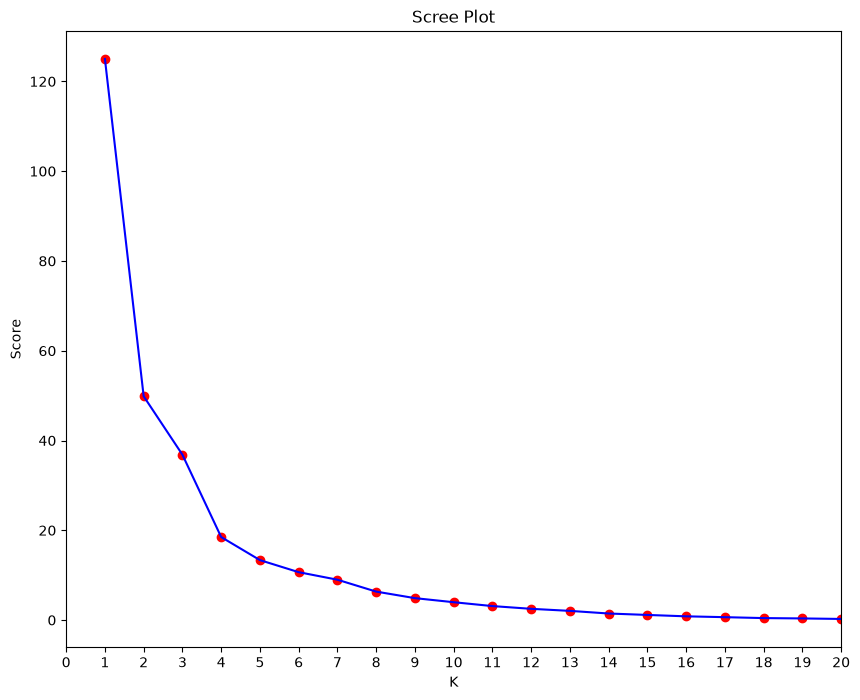

In [20]:
plt.figure(figsize=(10,8))
plt.scatter(df_wss["K"],df_wss["Score"],c='red')
plt.plot(df_wss["K"],df_wss["Score"],c='blue')
plt.title("Scree Plot")
plt.xlim(1, 20)         
plt.xticks(range(0, 21))
plt.xlabel("K")
plt.ylabel("Score")
plt.show()